In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
df = pd.read_csv('/content/loan_approval_dataset.csv')

In [28]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [29]:
df.tail()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved
4268,4269,1,Graduate,No,9200000,29700000,10,607,17800000,11800000,35700000,12000000,Approved


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1   no_of_dependents           4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [31]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
loan_id,4269.0,2.135000e+03,1.232498e+03,1.0,1068.0,2135.0,3202.0,4269.0
no_of_dependents,4269.0,2.498712e+00,1.695910e+00,0.0,1.0,3.0,4.0,5.0
income_annum,4269.0,5.059124e+06,2.806840e+06,200000.0,2700000.0,5100000.0,7500000.0,9900000.0
loan_amount,4269.0,1.513345e+07,9.043363e+06,300000.0,7700000.0,14500000.0,21500000.0,39500000.0
loan_term,4269.0,1.090045e+01,5.709187e+00,2.0,6.0,10.0,16.0,20.0
cibil_score,4269.0,5.999361e+02,1.724304e+02,300.0,453.0,600.0,748.0,900.0
residential_assets_value,4269.0,7.472617e+06,6.503637e+06,-100000.0,2200000.0,5600000.0,11300000.0,29100000.0
commercial_assets_value,4269.0,4.973155e+06,4.388966e+06,0.0,1300000.0,3700000.0,7600000.0,19400000.0
luxury_assets_value,4269.0,1.512631e+07,9.103754e+06,300000.0,7500000.0,14600000.0,21700000.0,39200000.0
bank_asset_value,4269.0,4.976692e+06,3.250185e+06,0.0,2300000.0,4600000.0,7100000.0,14700000.0


In [32]:
df.isnull().sum()

,0
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


In [33]:
df.duplicated().sum()

np.int64(0)

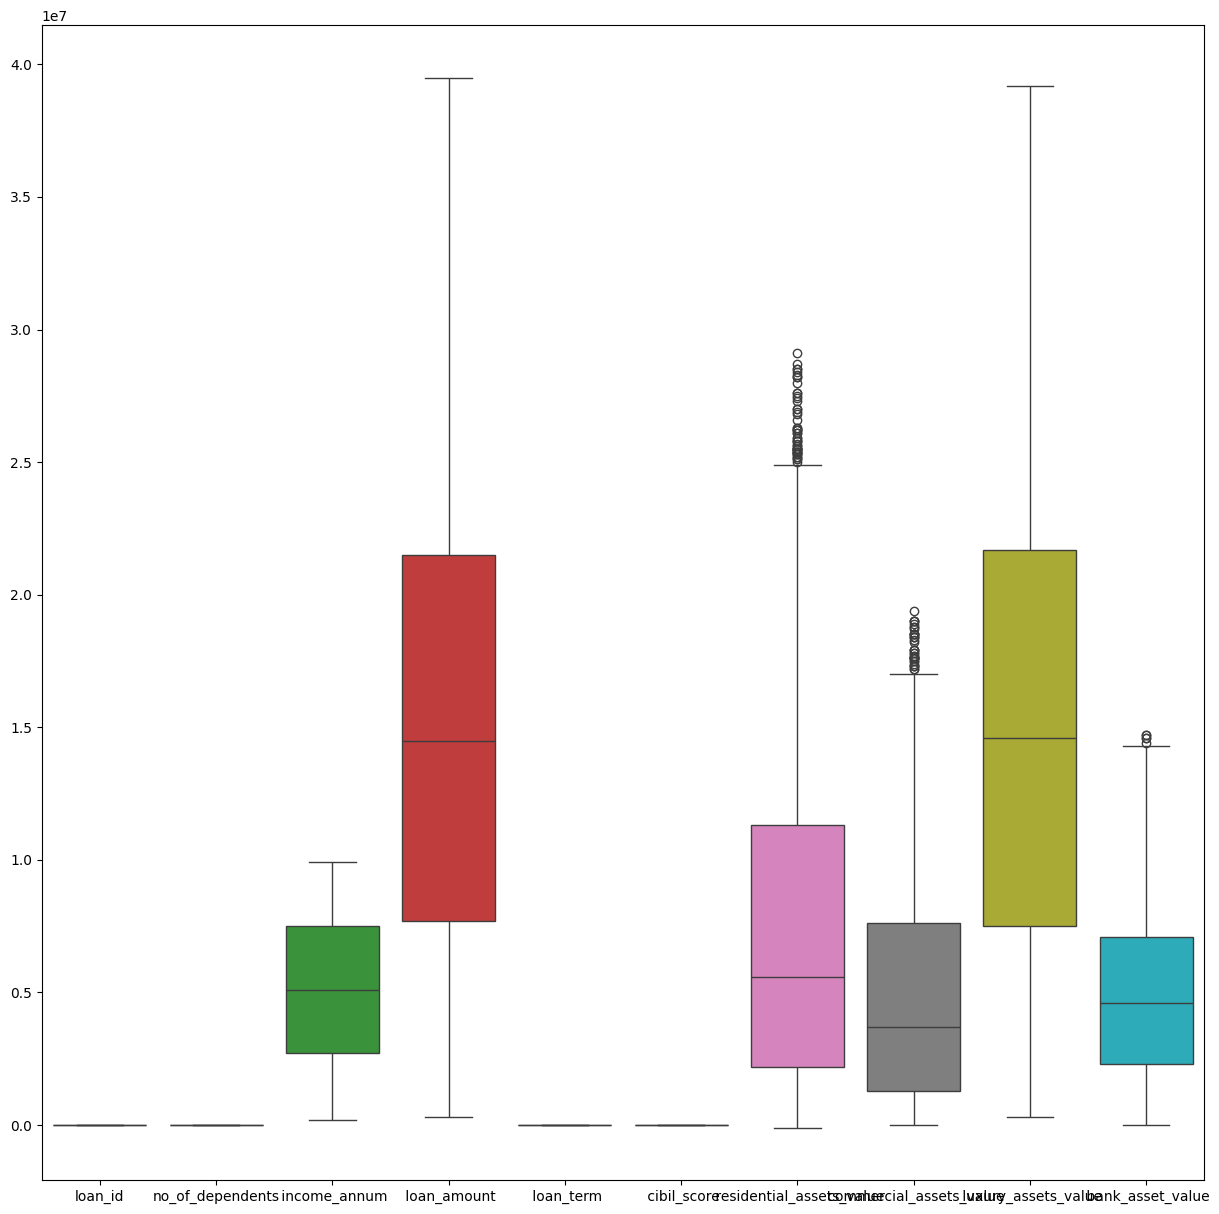

In [34]:
plt.figure(figsize=(15,15))
sns.boxplot(data = df.select_dtypes(include='number'))
plt.show()

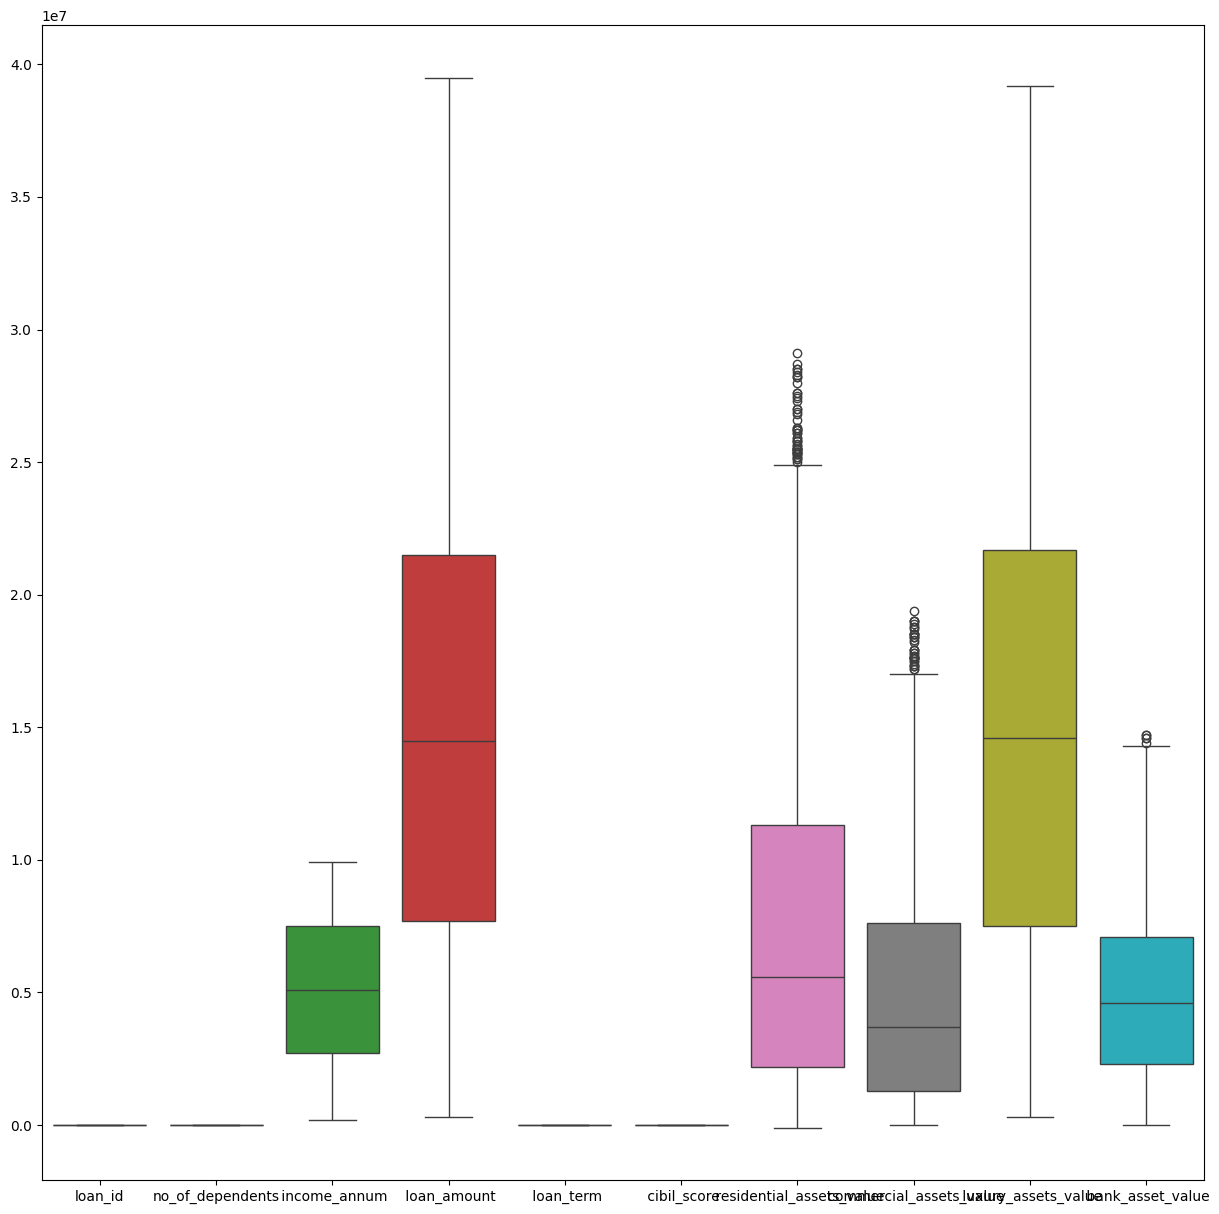

In [35]:
# for loop
for col in df.select_dtypes(include ='number').columns:
  if col == "loan_id":
    continue
plt.figure(figsize=(15,15))
sns.boxplot(data = df.select_dtypes(include='number'))
plt.show()

In [36]:
# Outlier treatment
df.columns = df.columns.str.strip()

columns = [
    'luxury_assets_value',
    'commercial_assets_value',
]

for i in columns:
  Q1 = df[i].quantile(0.25)
  Q3 = df[i].quantile(0.75)
  IQR = Q3-Q1
  lower_bound = Q1 - 1.5*IQR
  upper_bound = Q3 + 1.5*IQR

  df[i] = np.where(df[i] < lower_bound, lower_bound, df[i])
  df[i] = np.where(df[i] > upper_bound, upper_bound, df[i])

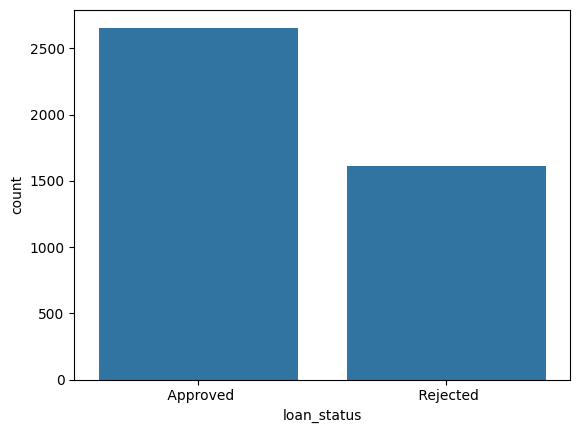

In [37]:
# Univariate Analysis
sns.countplot(data=df, x='loan_status')
plt.show()

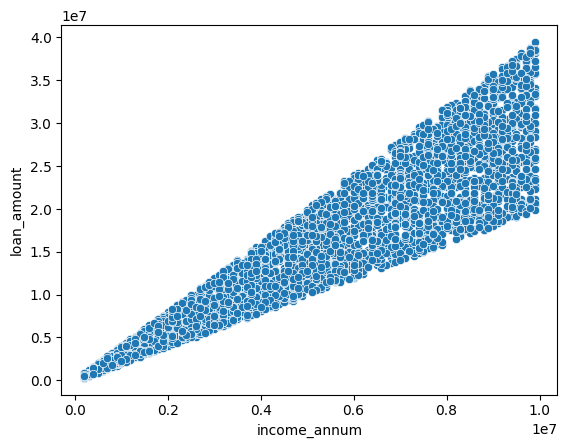

In [38]:
sns.scatterplot(x = df['income_annum'],y= df['loan_amount'])
plt.show()

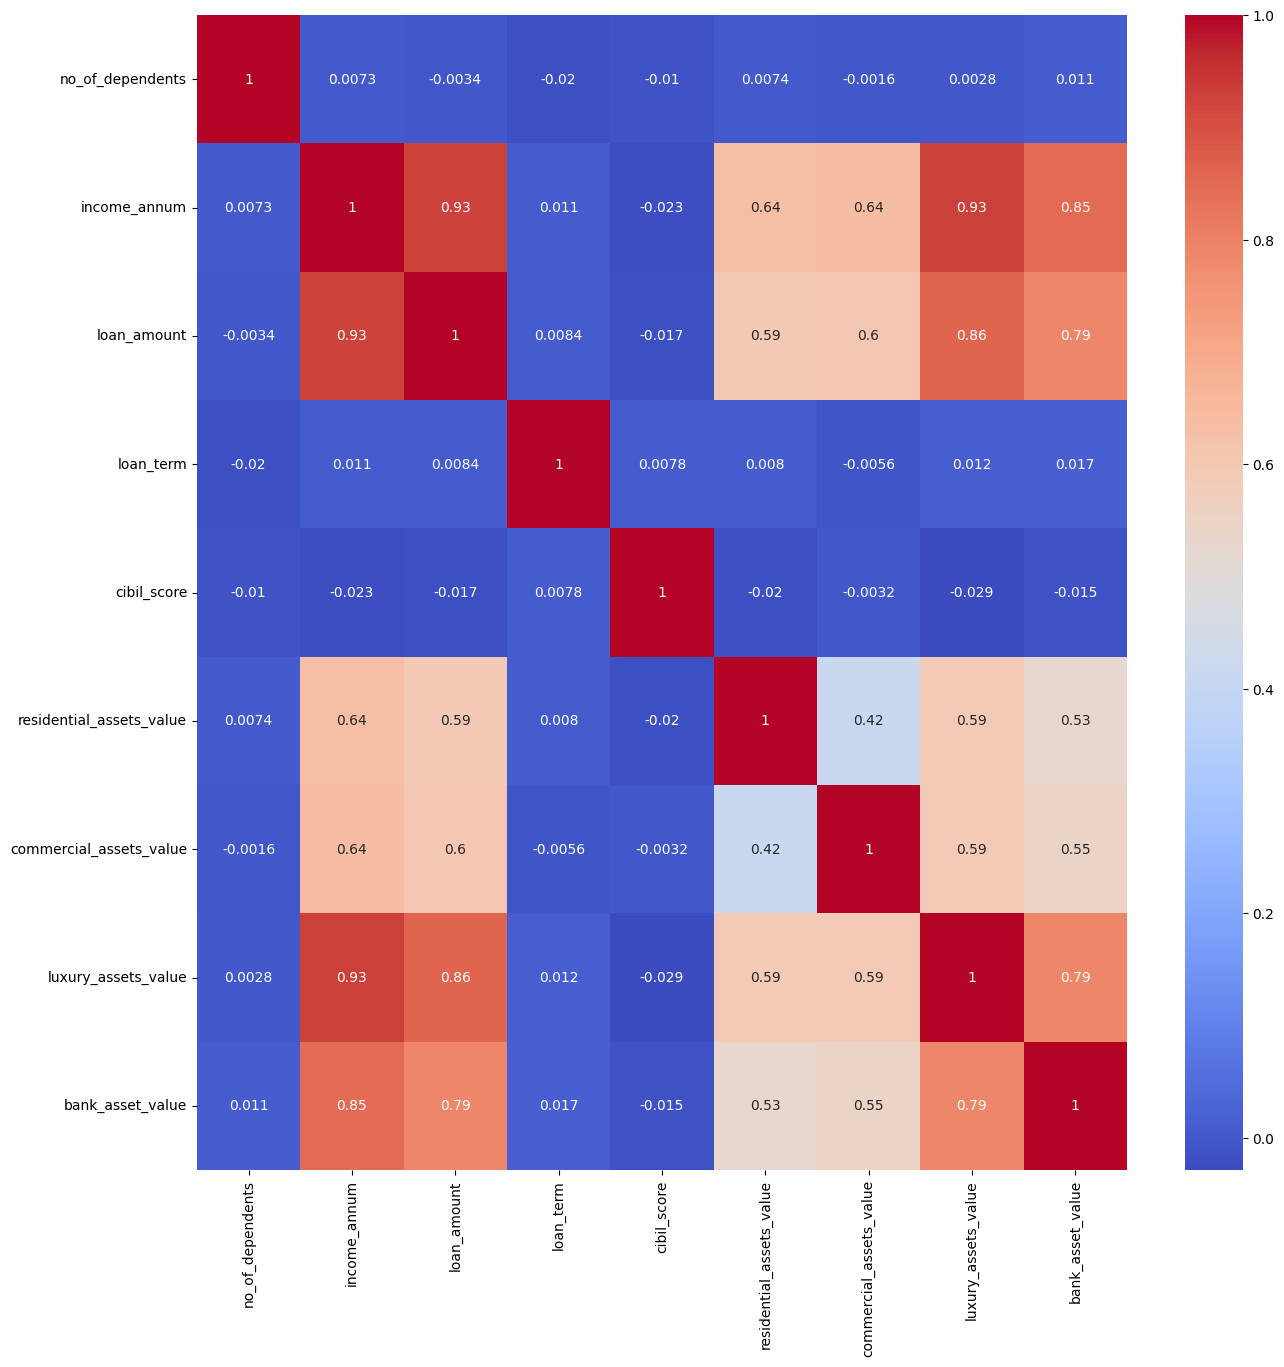

In [39]:
plt.figure(figsize=(15,15))
sns.heatmap(df.select_dtypes(include='number').drop(columns = 'loan_id',errors ='ignore').corr(), annot=True,cmap =  'coolwarm')
plt.show()



In [40]:
df.select_dtypes(include ='object').columns

Index(['education', 'self_employed', 'loan_status'], dtype='object')

In [42]:
print(df['loan_status'].value_counts(dropna = False))

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [43]:
print(df['self_employed'].value_counts(dropna = False))

self_employed
Yes    2150
No     2119
Name: count, dtype: int64


In [44]:
print(df['education'].value_counts(dropna = False))

education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64


In [45]:
df.columns = df.columns.str.strip()
for  col in df.select_dtypes(include ='object').columns:
     df[col] = df[col].str.strip()

In [46]:
df['education'] = df['education'].map({'Graduate': 1, 'Not Graduate': 0})
df['self_employed'] = df['self_employed'].map({'Yes': 1, 'No': 0})
df['loan_status'] = df['loan_status'].map({'Approved': 1, 'Rejected': 0})

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   loan_id                   4269 non-null   int64  
 1   no_of_dependents          4269 non-null   int64  
 2   education                 4269 non-null   int64  
 3   self_employed             4269 non-null   int64  
 4   income_annum              4269 non-null   int64  
 5   loan_amount               4269 non-null   int64  
 6   loan_term                 4269 non-null   int64  
 7   cibil_score               4269 non-null   int64  
 8   residential_assets_value  4269 non-null   int64  
 9   commercial_assets_value   4269 non-null   float64
 10  luxury_assets_value       4269 non-null   float64
 11  bank_asset_value          4269 non-null   int64  
 12  loan_status               4269 non-null   int64  
dtypes: float64(2), int64(11)
memory usage: 433.7 KB


In [48]:
# Divide the dataset into X, & Y
X = df.drop(columns=['loan_id','loan_status'])
Y = df['loan_status']

In [49]:
# Train_Test
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)


In [50]:
# Model
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
model.fit(X_train,Y_train)

RandomForestClassifier()

In [51]:
y_pred = model.predict(X_test)

In [52]:
print(y_pred[:10])

[0 1 0 1 1 1 1 0 1 0]


In [53]:
result = pd.DataFrame({'Actual':Y_test,'Predicted':y_pred})
result.head(10)

,Actual,Predicted
1703,0,0
1173,1,1
308,0,0
1322,1,1
3271,1,1
3539,1,1
1522,1,1
3399,0,0
1402,1,1
1829,0,0


In [54]:
from sklearn.metrics import accuracy_score
accuracy_score(Y_test,y_pred)


0.9800936768149883

In [55]:
train_accuray = model.score(X_train,Y_train)
test_accuracy = model.score(X_test,Y_test)
print(train_accuray,test_accuracy)

1.0 0.9800936768149883


In [56]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(Y_test,y_pred)
print(cm)

[[306  12]
 [  5 531]]


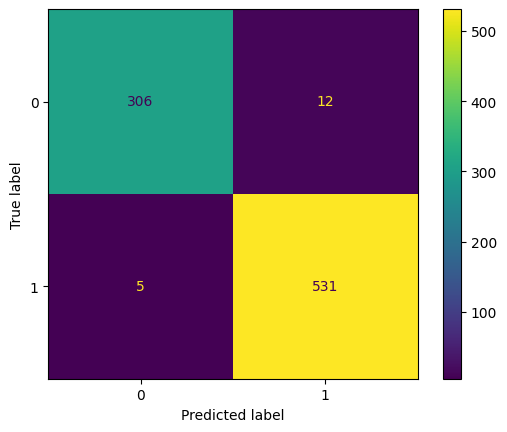

In [57]:
from sklearn.metrics import ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=model.classes_)
disp.plot()
plt.show()

In [58]:
from sklearn.metrics import classification_report
print(classification_report(Y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       318
           1       0.98      0.99      0.98       536

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



In [59]:
# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100,50, 150, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(),
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, Y_train)



Fitting 5 folds for each of 144 candidates, totalling 720 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 50, 150, 200]},
             verbose=1)

In [60]:
print(grid.best_params_)
print(grid.best_score_)

{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
0.9806734992679356


In [63]:
best_model = grid.best_estimator_

print("Training Accuracy:", best_model.score(X_train, Y_train))
print("Testing Accuracy:", best_model.score(X_test, Y_test))

Training Accuracy: 0.9967789165446559
Testing Accuracy: 0.9754098360655737


In [65]:
print("Before Tuning:", model.score(X_test, Y_test))
print("After Tuning:", best_model.score(X_test, Y_test))

Before Tuning: 0.9800936768149883
After Tuning: 0.9754098360655737
